# Member 2: Embeddings and Vector Database, step by step

This notebook walks through the retrieval layer of the NSBM Academic Administration RAG system and shows the maths behind every score:

1. Setup and building the vector database from Member 1's chunks
2. Vector maths by hand: magnitude, dot product, normalisation, cosine
3. TF-IDF written from scratch
4. Hybrid search: dense + sparse, fused with Reciprocal Rank Fusion
5. The full score trace of one search
6. What the agent receives from `search()`
7. Choosing the agent's refusal threshold (`min_score`)
8. The tests

**How to run:** in Google Colab, choose *Runtime → Run all*. It also runs locally in VS Code from the project's `notebooks/` folder, with the project's venv as the kernel (`pip install ipykernel matplotlib` first). The first run downloads the MiniLM model (about 80 MB).

## 1. Setup

In [1]:
import os
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.exists("/content/RAG---NSBM"):
        get_ipython().system("git clone -q https://github.com/esala714/RAG---NSBM.git /content/RAG---NSBM")
    os.chdir("/content/RAG---NSBM")
    get_ipython().system("pip install -q chromadb==1.5.9 pypdf python-docx python-dotenv")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")              # work from the project root, like the scripts

sys.path.insert(0, os.getcwd())
print("Project folder:", os.getcwd())

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
tweepy 4.17.0 requires oauthlib<4,>=3.2.0, but you have oauthlib 4.0.1 which is incompatible.
Project folder: /content/RAG---NSBM


### Build the vector database

`build_index.py` reads Member 1's `data/processed/chunks.jsonl`, embeds every chunk with MiniLM (384 numbers per chunk, each vector of length 1) and stores the text, the metadata and the vector in a persistent Chroma collection that uses cosine distance. `--reset` deletes the old collection first.

In [2]:
!python scripts/build_index.py --reset

Read 155 chunks (155 unique). Embedding with all-MiniLM-L6-v2 ...
/root/.cache/chroma/onnx_models/all-MiniLM-L6-v2/onnx.tar.gz: 100% 79.3M/79.3M [00:02<00:00, 33.7MiB/s]

Upserted 155 chunks into 'nsbm_admin_minilm' at vector_db/
  academic_calendar              3
  academic_policies             92
  attendance                     4
  examinations                  45
  registration                   6
  staff                          5
Collection now holds 155 vectors.

Example stored vector  id=NSBM_academic_appeals_policy-p1-c1-6297684b0e
  dimension = 384,  ||d|| = 1.0000,  first 5 values = [-0.0013, 0.0356, -0.0703, -0.0588, -0.0248]
  TF-IDF vocabulary = 2390 terms over 155 chunks


## 2. Vector maths by hand

The dense score is the cosine of the angle between the question vector $q$ and a chunk vector $d$:

$$\lVert v \rVert = \sqrt{\textstyle\sum_i v_i^2} \qquad q \cdot d = \textstyle\sum_i q_i d_i \qquad \cos(q, d) = \frac{q \cdot d}{\lVert q \rVert \, \lVert d \rVert}$$

`src/retrieval/vector_math.py` writes these out with NumPy. First on small vectors that can be checked on paper:

In [3]:
from src.retrieval.vector_math import cosine, dot, explain_cosine, magnitude, normalize

a, b = [3, 4], [4, 3]
print(f"||a|| = sqrt(3^2 + 4^2) = {magnitude(a)}")
print(f"a . b = 3*4 + 4*3 = {dot(a, b)}")
print(f"cos(a, b) = 24 / (5 x 5) = {cosine(a, b):.2f}")
print(f"normalize(a) = {normalize(a)}, its length = {magnitude(normalize(a)):.1f}")
print(f"Same direction, different length: cos([2, 2], [5, 5]) = {cosine([2, 2], [5, 5]):.1f}")

||a|| = sqrt(3^2 + 4^2) = 5.0
a . b = 3*4 + 4*3 = 24.0
cos(a, b) = 24 / (5 x 5) = 0.96
normalize(a) = [0.6 0.8], its length = 1.0
Same direction, different length: cos([2, 2], [5, 5]) = 1.0


Now on real vectors: the question is embedded with MiniLM, Chroma returns the nearest chunk with its stored vector, and the cosine is recomputed by hand. Chroma's own cosine distance must equal $1 - \cos$.

In [4]:
from src.retrieval import build_retriever

retriever = build_retriever()           # MiniLM + the Chroma store built above (hybrid mode)
store = retriever.store

question = "How late can a candidate enter the examination room after the exam has started?"
q = store.embedder.embed_query(question)
print(f"Question vector: {len(q)} numbers, first five {q[:5].round(4)}")

hit = store.search_by_vector(q, k=1)[0]
e = explain_cosine(q, hit.embedding)
print(f"\nNearest chunk: {hit.metadata['source']}, page {hit.metadata['page']}")
print(f"q . d = {e.dot:.4f}   ||q|| = {e.norm_a:.4f}   ||d|| = {e.norm_b:.4f}")
print(f"cos = q . d / (||q|| x ||d||) = {e.cosine:.4f}")
print(f"Chroma distance = {hit.distance:.4f}  ->  1 - distance = {1 - hit.distance:.4f}")

Question vector: 384 numbers, first five [ 0.0894  0.0079 -0.066   0.0032 -0.0143]

Nearest chunk: Examination Regulations_Instructions To Candidates.pdf, page 2
q . d = 0.6932   ||q|| = 1.0000   ||d|| = 1.0000
cos = q . d / (||q|| x ||d||) = 0.6932
Chroma distance = 0.3068  ->  1 - distance = 0.6932


Both vectors have length 1 (MiniLM normalises them), so here the cosine is simply the dot product.

## 3. TF-IDF written from scratch

The sparse side scores exact words. `src/retrieval/sparse_index.py` builds it with NumPy only:

$$\text{tf} = 1 + \log(\text{count}) \qquad \text{idf} = \log\frac{1 + N}{1 + \text{df}} + 1 \qquad \text{weight} = \text{tf} \times \text{idf}$$

$N$ is the number of chunks and df the number of chunks that contain the word, so rare words weigh more. Every vector is divided by its length, so the TF-IDF cosine is the sum of $q_i \times d_i$ over the words the question and the chunk share.

In [5]:
import numpy as np
from src.retrieval.sparse_index import tokenize

retriever.refresh_sparse_index()        # rebuilt from what Chroma stores
tfidf = retriever.sparse
N = tfidf.n_docs
print(f"{N} chunks, vocabulary of {tfidf.vocabulary_size} words")
print("tokenize() lower-cases, removes stop words and trims endings:")
print("  ", tokenize("Candidates shall be admitted to the examination rooms"))

print()
for word in ["examination", "invigilator"]:
    term = tokenize(word)[0]
    i = tfidf.vocabulary[term]
    df = int((tfidf.matrix[:, i] > 0).sum())
    print(f"{term:<12} df = {df:>3}   idf = log((1 + {N}) / (1 + {df})) + 1 = {tfidf.idf[i]:.3f}")

155 chunks, vocabulary of 2390 words
tokenize() lower-cases, removes stop words and trims endings:
   ['candidate', 'admitted', 'examination', 'room']

examination  df =  63   idf = log((1 + 155) / (1 + 63)) + 1 = 1.891
invigilator  df =  10   idf = log((1 + 155) / (1 + 10)) + 1 = 3.652


In [6]:
sq = tfidf.vectorize(question)
print("Question weights before normalisation:", [(t, round(w, 2)) for t, w in sq.weights])
print(f"||q_raw|| = {sq.raw_norm:.4f}  ->  q_hat = q_raw / {sq.raw_norm:.4f}, length {np.linalg.norm(sq.unit):.4f}")

best = tfidf.search(sq, 1)[0]
parts = tfidf.term_contributions(sq, best.chunk_id, top=100)
print(f"\nBest TF-IDF chunk: cosine = {best.cosine:.4f}")
print("  = " + " + ".join(f"{t}:{w:.3f}" for t, w in parts) + f" = {sum(w for _, w in parts):.4f}")

Question weights before normalisation: [('started', 5.36), ('late', 4.95), ('enter', 4.1), ('room', 3.56), ('after', 3.34), ('exam', 3.22), ('candidate', 2.22), ('examination', 1.89)]
||q_raw|| = 10.6200  ->  q_hat = q_raw / 10.6200, length 1.0000

Best TF-IDF chunk: cosine = 0.2053
  = room:0.072 + enter:0.040 + candidate:0.036 + examination:0.030 + after:0.027 = 0.2053


## 4. Hybrid search and Reciprocal Rank Fusion

Dense search finds meaning, sparse search finds exact words. The two scores are on different scales, so they are fused by rank only, with $k = 60$:

$$\text{RRF}(d) = \frac{1}{60 + \text{rank}_\text{dense}(d)} + \frac{1}{60 + \text{rank}_\text{sparse}(d)}$$

In Member 1's first evaluation run, TF-IDF alone missed this question (q05): the word "examination" ranks the long examination-rules documents above the one-page fee table.

In [7]:
question_fee = "How much is the repeat examination fee for an NSBM degree programme?"
for mode in ["sparse", "dense", "hybrid"]:
    result = retriever.retrieve(question_fee, k=4, mode=mode)
    print(f"\n{mode.upper()}")
    for c in result.chunks:
        s = c.scores
        print(f"  #{c.rank} {c.citation[:58]:<58} dense rank {s.dense_rank or '-':>2}"
              f"  sparse rank {s.sparse_rank or '-':>2}  RRF {s.rrf_score:.5f}")


SPARSE
  #1 NSBM Green University enforces structured examination regu dense rank  -  sparse rank  1  RRF 0.01639
  #2 NSBM Assessment Guideline.pdf, page 2                      dense rank  -  sparse rank  2  RRF 0.01613
  #3 NSBM student handbook 7.pdf, page 16                       dense rank  9  sparse rank  3  RRF 0.03037
  #4 NSBM Course registration guideline.pdf, page 2             dense rank  -  sparse rank  4  RRF 0.01562

DENSE
  #1 Criteria for Assessment of MBS Programmes (NSBM).pdf, page dense rank  1  sparse rank  -  RRF 0.01639
  #2 Criteria for Assessment of MBS Programmes (NSBM).pdf, page dense rank  2  sparse rank  -  RRF 0.01613
  #3 NSBM Degree Programmes_Exam By Laws _ Version 1 (17.2 onwa dense rank  3  sparse rank  -  RRF 0.01587
  #4 Criteria for Assessment of Postgraduate Diploma  Programme dense rank  4  sparse rank  -  RRF 0.01562

HYBRID
  #1 NSBM student handbook 7.pdf, page 16                       dense rank  9  sparse rank  3  RRF 0.03037
  #2 Revision 

## 5. The full score trace of one search

`explain()` prints every number behind each retrieved chunk. This is the printout used in the video.

In [8]:
print(retriever.retrieve(question, k=3).explain())

QUERY : "How late can a candidate enter the examination room after the exam has started?"
MODE  : hybrid (RRF k=60) | category filter: none | 703 ms
DENSE : model=all-MiniLM-L6-v2, dim=384, ||q|| = 1.0000
SPARSE: query TF-IDF weights before normalisation: started=5.36, late=4.95, enter=4.10, room=3.56, after=3.34, exam=3.22, candidate=2.22, examination=1.89
        ||q_raw|| = 10.6200  ->  q_hat = q_raw / 10.6200  (unit length)
------------------------------------------------------------------------------
#1  Examination Regulations_Instructions To Candidates.pdf, page 2  [examinations]  id=Examination_Regulations_Instructions_To_-p2-c1-24e6a59689
    dense : q.d = 0.6932   ||q|| = 1.0000   ||d|| = 1.0000
            cos = q.d / (||q|| x ||d||) = 0.6932   [Chroma distance 0.3068 -> 1 - dist = 0.6932]
    sparse: TF-IDF cos = 0.2053   shared terms (q_i x d_i): room:0.072, enter:0.040, candidate:0.036, examination:0.030, after:0.027
    fusion: dense rank 1, sparse rank 1  ->  RRF = 1/(6

## 6. What the agent receives: `search()`

`HybridRetriever` implements the team interface `BaseRetriever`, so Member 3's agent calls `search(query, top_k)`. Each chunk's `score` is its dense cosine (0 to 1), the number the agent compares with `min_score`, and `extra` keeps all the other numbers for the agent's trace.

In [9]:
chunks = retriever.search("Can I take my mobile phone into the examination room?", top_k=4)
for c in chunks:
    page = f", page {c.page}" if c.page else ""
    print(f"score {c.score:.3f}   {c.source}{page}")

print("\nextra of the first chunk:")
for key, value in chunks[0].extra.items():
    print(f"  {key:<16} {value}")

score 0.587   Examination Regulations_Instructions To Candidates.pdf, page 3
score 0.542   Examination Regulations_Instructions To Candidates.pdf, page 3
score 0.507   NSBM Green University enforces structured examination regula.pdf, page 1
score 0.434   Examination Regulations_Instructions To Candidates.pdf, page 2

extra of the first chunk:
  chunk_id         Examination_Regulations_Instructions_To_-p3-c2-fe040f3e90
  category         examinations
  rank             1
  mode             hybrid
  embedding_model  all-MiniLM-L6-v2
  dot              0.586917
  query_norm       1.0
  chunk_norm       1.0
  dense_cosine     0.586917
  chroma_distance  0.413083
  sparse_cosine    0.29464
  sparse_terms     [['phone', 0.098094], ['room', 0.089111], ['mobile', 0.073843], ['examination', 0.033593]]
  dense_rank       1
  sparse_rank      1
  rrf_score        0.032787
  fusion_formula   1/(60+1) + 1/(60+1)


## 7. Choosing the agent's refusal threshold (`min_score`)

The agent answers only when a retrieved chunk scores at least `min_score`. `scripts/calibrate_threshold.py` asks Member 1's ground-truth questions (14 answerable, 3 unanswerable) and 7 more questions that no document answers, and picks the threshold with the best **balanced accuracy**:

$$\text{balanced}(t) = \frac{1}{2}\left(\frac{\#\text{answerable with score} \ge t}{\#\text{answerable}} + \frac{\#\text{unanswerable with score} < t}{\#\text{unanswerable}}\right)$$

Both groups count equally, so "answer everything" cannot win just because there are more answerable questions. Of the best gaps between neighbouring scores, the widest is kept and its middle is used (largest margin).

In [10]:
!python scripts/calibrate_threshold.py

Mode = hybrid, k = 4, 155 chunks, model = all-MiniLM-L6-v2
Score = best dense cosine of the k chunks, the number the agent compares with min_score
------------------------------------------------------------------------------
ID   Group         Score Right doc  Question
q01  answerable    0.693       yes  How late can a candidate enter the examination
q02  answerable    0.587       yes  Can I take my mobile phone into the examinatio
q03  answerable    0.574       yes  What is the minimum attendance students must m
q04  answerable    0.668       yes  How many days after an exam do I have to submi
q05  answerable    0.620       yes  How much is the repeat examination fee for an 
q06  answerable    0.552       yes  How long do I have to submit repeat coursework
q07  answerable    0.779       yes  How is GPA calculated at NSBM?
q08  answerable    0.772       yes  What is the minimum GPA needed for First Class
q09  answerable    0.414       yes  What overall mark is needed to pass a module?

In [11]:
import importlib.util

import matplotlib.pyplot as plt
from src.evaluation.evaluate import load_ground_truth
from src.retrieval.threshold import choose_threshold

spec = importlib.util.spec_from_file_location("calibrate_threshold", "scripts/calibrate_threshold.py")
calibrate = importlib.util.module_from_spec(spec)
spec.loader.exec_module(calibrate)       # reuse its extra questions; main() does not run

questions = [(q["id"], q["question"], q["answerable"]) for q in load_ground_truth()]
questions += [(qid, text, False) for qid, text in calibrate.EXTRA_UNANSWERABLE]
score = {qid: max((c.score for c in retriever.search(text, top_k=4)), default=0.0)
         for qid, text, _ in questions}
answerable = [qid for qid, _, ok in questions if ok]
unanswerable = [qid for qid, _, ok in questions if not ok]
choice = choose_threshold([score[q] for q in answerable], [score[q] for q in unanswerable])
suggested = round(choice.threshold, 2)
print(f"Best min_score on these scores = {suggested:.2f}: {choice.answered}/{len(answerable)} answerable answered, "
      f"{choice.refused}/{len(unanswerable)} unanswerable refused, "
      f"balanced accuracy {choice.balanced_accuracy:.3f}")

Best min_score on these scores = 0.54: 11/14 answerable answered, 10/10 unanswerable refused, balanced accuracy 0.893


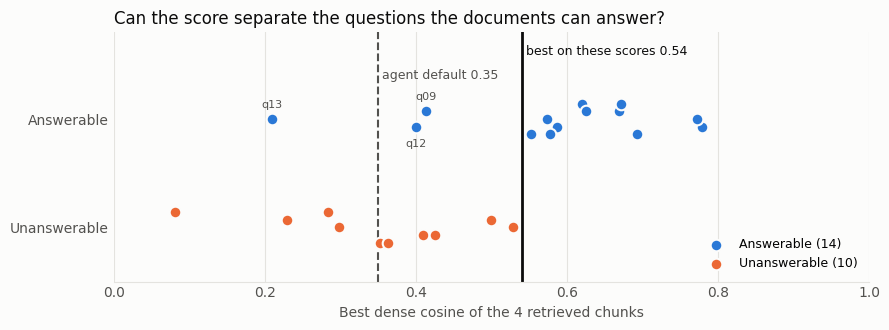

In [12]:
BLUE, ORANGE = "#2a78d6", "#eb6834"                     # categorical slots 1 and 2
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"

fig, ax = plt.subplots(figsize=(9, 3.4), facecolor=SURFACE)
ax.set_facecolor(SURFACE)
rows = [(0, "Unanswerable", unanswerable, ORANGE), (1, "Answerable", answerable, BLUE)]
for row, group, ids, color in rows:
    ys = [row + ((i % 5) - 2) * 0.07 for i in range(len(ids))]       # small spread so dots do not hide each other
    xs = [score[q] for q in ids]
    ax.scatter(xs, ys, s=70, color=color, edgecolors=SURFACE, linewidths=1.5,
               label=f"{group} ({len(ids)})", zorder=3)
    wrong = [(q, x, y) for q, x, y in zip(ids, xs, ys) if (x >= suggested) != (row == 1)]
    if len(wrong) > 4:                       # too many to label clearly: the list above names them
        wrong = []
    for n, (q, x, y) in enumerate(wrong):                            # label only the misjudged questions
        ax.annotate(q, (x, y), textcoords="offset points", xytext=(0, 8 if n % 2 == 0 else -15),
                    ha="center", fontsize=8, color=MUTED)

ax.axvline(suggested, color=INK, linewidth=2, zorder=2)
ax.axvline(0.35, color=MUTED, linewidth=1.5, linestyle="--", zorder=2)
ax.text(suggested, 1.62, f" best on these scores {suggested:.2f}", color=INK, fontsize=9, va="center")
ax.text(0.35, 1.40, " agent default 0.35", color=MUTED, fontsize=9, va="center")

ax.set_yticks([0, 1], ["Unanswerable", "Answerable"], color=INK)
ax.set_ylim(-0.5, 1.8)
ax.set_xlim(0, 1)
ax.set_xlabel("Best dense cosine of the 4 retrieved chunks", color=MUTED)
ax.set_title("Can the score separate the questions the documents can answer?", color=INK, loc="left")
ax.grid(axis="x", color=GRID, linewidth=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors=MUTED, length=0)
for side in ["top", "right", "left"]:
    ax.spines[side].set_visible(False)
ax.spines["bottom"].set_color(GRID)
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], labels[::-1], loc="lower right", frameon=False, fontsize=9)   # same order as the rows
plt.tight_layout()
plt.show()

Dots to the right of the solid line pass the best threshold on these scores. Labelled dots are misjudged at that threshold: blue ones would be refused although the documents answer them, orange ones would reach Gemini although no document answers them.

These are retrieval scores only. The agent searches with the queries Gemini plans, keeps only chunks above `min_score` as context, and Gemini refuses when the context lacks the answer. The end-to-end check in `README_member2.md` (`python -m src.evaluation.evaluate --retriever hybrid --with-agent --min-score ...`) found that 0.35 answered more questions than 0.54 while Gemini still refused all three unanswerable ones, so the agent keeps `min_score` = 0.35.

## 8. The tests

The retrieval tests use a small fake embedder, so they run in seconds without the model. The agent tests run Member 3's real agent on the real retriever with a scripted LLM.

In [13]:
!python -m pytest -q tests

.......................................................                  [100%]
55 passed in 9.31s


## Summary

- Dense scores are cosines recomputed by hand and checked against Chroma's distance; TF-IDF scores are sums of $q_i \times d_i$; the two are fused by rank with RRF.
- On Member 1's evaluation questions, hybrid search finds the right document more often than TF-IDF alone (the numbers are in `README_member2.md`).
- `search()` gives the agent the dense cosine as its score, and the threshold for refusing comes from the data, not from a guess.